# Mission 2 — Audit et préparation des données
**TP Customer Intelligence & AI Marketing Strategy — cas NovaMarket**

**Objectif :** vérifier que les 4 fichiers sont fiables avant toute modélisation, documenter chaque transformation et préparer une table clients enrichie pour les missions 3 et 4.

**Plan**

0. Mise en place
1. Chargement des 4 fichiers
2. Dimensions, types, doublons, valeurs manquantes
3. Contrôle des bornes
4. Cohérence entre les fichiers
5. Cas particulier : les clients sans commande
6. Distributions et valeurs extrêmes
7. Transformations et préparation
8. Journal des transformations
9. Limites de représentativité
10. Synthèse de l'audit

## 0. Mise en place

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Dans Colab : connexion au Google Drive. En local : dossier du projet.
try:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE = '/content/drive/MyDrive/TP_NovaMarket'
except ImportError:
    BASE = os.environ.get('TP_BASE', '..')

DATA = os.path.join(BASE, 'data')
OUT = os.path.join(BASE, 'outputs')
os.makedirs(OUT, exist_ok=True)

RANDOM_STATE = 42          # reproductibilité
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 200)
sns.set_theme(style='whitegrid')

## 1. Chargement des 4 fichiers
On charge les fichiers **sans conversion** pour voir les types tels qu'ils sont stockés.

In [2]:
customers    = pd.read_csv(os.path.join(DATA, 'customers.csv'))
transactions = pd.read_csv(os.path.join(DATA, 'transactions.csv'))
reviews      = pd.read_csv(os.path.join(DATA, 'reviews.csv'))
content      = pd.read_csv(os.path.join(DATA, 'content_performance.csv'))

fichiers = {'customers': customers, 'transactions': transactions,
            'reviews': reviews, 'content_performance': content}

for nom, df in fichiers.items():
    print(f'--- {nom} ---')
    display(df.head(3))

--- customers ---


,customer_id,age,region,acquisition_channel,days_since_last_order,orders_12m,avg_order_value_eur,revenue_12m_eur,sessions_90d,emails_received_90d,email_clicks_90d,returns_12m,support_tickets_90d,satisfaction_score,churn_90d
0,C00001,58,Hauts-de-France,Direct,166,3,44.18,132.55,28,13,4,1,3,2.4,1
1,C00002,52,Occitanie,Email,55,4,74.79,299.16,52,5,0,0,0,3.1,0
2,C00003,66,Nouvelle-Aquitaine,SEO,13,2,75.32,150.63,9,1,0,0,1,4.2,0


--- transactions ---


,transaction_id,customer_id,date,product_category,amount_eur,device
0,T0000001,C00001,2025-05-25,Soin visage,28.33,web
1,T0000002,C00001,2025-07-27,Soin corps,49.14,mobile
2,T0000003,C00001,2025-06-26,Maquillage,36.78,web


--- reviews ---


,review_id,customer_id,review_text,date
0,R00001,C00326,Commande incomplète et remboursement compliqué,2025-01-15
1,R00002,C00314,Conforme à mes attentes,2025-02-02
2,R00003,C00972,J'adore cette marque et les nouveautés,2025-04-10


--- content_performance ---


,content_id,publication_date,channel,content_type,reach,clicks,interactions,conversions,cost_eur
0,POST001,2025-01-01,Instagram,promotion,10215,302,600,32,239.78
1,POST002,2025-01-09,LinkedIn,promotion,7897,181,1120,16,408.92
2,POST003,2025-01-17,Instagram,education,28519,518,3982,16,309.19


## 2. Dimensions, types, doublons et valeurs manquantes
Le tableau ci-dessous résume la qualité de chaque fichier. La 1ʳᵉ colonne de chaque fichier est son identifiant : on vérifie qu'il est unique.

In [3]:
resume = []
for nom, df in fichiers.items():
    resume.append({
        'fichier': nom,
        'lignes': df.shape[0],
        'colonnes': df.shape[1],
        'lignes_dupliquées': df.duplicated().sum(),
        'identifiants_dupliqués': df.iloc[:, 0].duplicated().sum(),
        'valeurs_manquantes': df.isna().sum().sum(),
    })
resume = pd.DataFrame(resume)
resume

,fichier,lignes,colonnes,lignes_dupliquées,identifiants_dupliqués,valeurs_manquantes
0,customers,1500,15,0,0,0
1,transactions,6815,6,0,0,0
2,reviews,700,4,0,0,0
3,content_performance,45,9,0,0,0


In [4]:
# Types de chaque colonne
for nom, df in fichiers.items():
    print(f'--- {nom} ---')
    print(df.dtypes.to_string(), '\n')

--- customers ---
customer_id                  str
age                        int64
region                       str
acquisition_channel          str
days_since_last_order      int64
orders_12m                 int64
avg_order_value_eur      float64
revenue_12m_eur          float64
sessions_90d               int64
emails_received_90d        int64
email_clicks_90d           int64
returns_12m                int64
support_tickets_90d        int64
satisfaction_score       float64
churn_90d                  int64 

--- transactions ---
transaction_id          str
customer_id             str
date                    str
product_category        str
amount_eur          float64
device                  str 

--- reviews ---
review_id      str
customer_id    str
review_text    str
date           str 

--- content_performance ---
content_id              str
publication_date        str
channel                 str
content_type            str
reach                 int64
clicks                int64
inte

**Constat :**
- **Aucun doublon** (ni ligne entière, ni identifiant) et **aucune valeur manquante** dans les 4 fichiers.
- Les colonnes `date` (transactions, reviews) et `publication_date` (content) sont lues comme du **texte** : il faudra les convertir en dates (étape 7).
- `region`, `acquisition_channel`, `product_category`, `device`, `channel` et `content_type` sont des **variables catégorielles** stockées en texte.

## 3. Contrôle des bornes
On écrit chaque règle métier et on compte les lignes qui la violent. Une règle respectée affiche **0**.

In [5]:
c, t, r, p = customers, transactions, reviews, content
t_dates = pd.to_datetime(t['date'], errors='coerce')
r_dates = pd.to_datetime(r['date'], errors='coerce')

regles = [
    # (fichier, règle, série booléenne = True si la ligne VIOLE la règle)
    ('customers', 'âge entre 18 et 100 ans',                 ~c['age'].between(18, 100)),
    ('customers', 'satisfaction entre 1 et 5',               ~c['satisfaction_score'].between(1, 5)),
    ('customers', 'churn_90d vaut 0 ou 1',                   ~c['churn_90d'].isin([0, 1])),
    ('customers', 'commandes ≥ 0',                           c['orders_12m'] < 0),
    ('customers', 'panier moyen > 0',                        c['avg_order_value_eur'] <= 0),
    ('customers', 'CA 12 mois ≥ 0',                          c['revenue_12m_eur'] < 0),
    ('customers', 'jours depuis dernière commande ≥ 0',      c['days_since_last_order'] < 0),
    ('customers', 'sessions ≥ 0',                            c['sessions_90d'] < 0),
    ('customers', 'clics email ≤ emails reçus',              c['email_clicks_90d'] > c['emails_received_90d']),
    ('customers', 'retours ≤ commandes',                     c['returns_12m'] > c['orders_12m']),
    ('customers', 'tickets support ≥ 0',                     c['support_tickets_90d'] < 0),
    ('transactions', 'montant > 0',                          t['amount_eur'] <= 0),
    ('transactions', 'date valide et en 2025',               t_dates.isna() | (t_dates.dt.year != 2025)),
    ('reviews', 'texte d\'avis non vide',                    r['review_text'].str.strip().eq('')),
    ('reviews', 'date valide et en 2025',                    r_dates.isna() | (r_dates.dt.year != 2025)),
    ('content', 'portée > 0',                                p['reach'] <= 0),
    ('content', 'clics ≤ portée (proxy des impressions)',    p['clicks'] > p['reach']),
    ('content', 'interactions ≤ portée',                     p['interactions'] > p['reach']),
    ('content', 'conversions ≤ clics',                       p['conversions'] > p['clicks']),
    ('content', 'coût > 0',                                  p['cost_eur'] <= 0),
]

controle_bornes = pd.DataFrame(
    [(f, regle, int(viol.sum())) for f, regle, viol in regles],
    columns=['fichier', 'règle', 'lignes_en_violation'])
controle_bornes['statut'] = np.where(controle_bornes['lignes_en_violation'] == 0, 'OK', 'À TRAITER')
controle_bornes

,fichier,règle,lignes_en_violation,statut
0,customers,âge entre 18 et 100 ans,0,OK
1,customers,satisfaction entre 1 et 5,0,OK
2,customers,churn_90d vaut 0 ou 1,0,OK
3,customers,commandes ≥ 0,0,OK
4,customers,panier moyen > 0,0,OK
5,customers,CA 12 mois ≥ 0,0,OK
6,customers,jours depuis dernière commande ≥ 0,0,OK
7,customers,sessions ≥ 0,0,OK
8,customers,clics email ≤ emails reçus,0,OK
9,customers,retours ≤ commandes,0,OK


In [6]:
# Valeurs minimales et maximales, pour illustrer les bornes réelles
display(customers.describe().T[['min', 'max', 'mean']].round(2))
display(content.describe().T[['min', 'max', 'mean']].round(2))

,min,max,mean
age,18.0,69.00,43.15
days_since_last_order,1.0,239.00,69.72
orders_12m,0.0,15.00,4.54
avg_order_value_eur,20.0,220.75,85.90
revenue_12m_eur,0.0,3311.19,475.88
sessions_90d,1.0,181.00,41.42
emails_received_90d,0.0,17.00,8.21
email_clicks_90d,0.0,9.00,1.52
returns_12m,0.0,5.00,0.40
support_tickets_90d,0.0,8.00,0.91


,min,max,mean
reach,1313.00,29484.00,14385.62
clicks,60.00,3126.00,933.82
interactions,59.00,4020.00,1418.33
conversions,3.00,304.00,60.84
cost_eur,83.02,797.94,447.43


**Constat :** les 20 règles sont respectées. La satisfaction varie de 1,1 à 5. Les montants sont tous positifs (minimum 12 € par transaction). Les clics ne dépassent jamais la portée, et les conversions ne dépassent jamais les clics.

Les bornes sont donc propres. Les vrais problèmes apparaissent quand on **croise** les fichiers (étape 4).

## 4. Cohérence entre les fichiers
On vérifie que les fichiers racontent la même histoire pour un même client.

In [7]:
ids_clients = set(customers['customer_id'])

coherence = {
    'transactions dont le client est absent de customers': (~transactions['customer_id'].isin(ids_clients)).sum(),
    'avis dont le client est absent de customers':          (~reviews['customer_id'].isin(ids_clients)).sum(),
    'clients sans aucune transaction':                      (~customers['customer_id'].isin(transactions['customer_id'])).sum(),
}

# Nombre de transactions par client vs orders_12m
nb_tx = transactions.groupby('customer_id').size()
cmp = customers.set_index('customer_id')[['orders_12m', 'revenue_12m_eur', 'avg_order_value_eur', 'days_since_last_order']].copy()
cmp['nb_transactions'] = nb_tx.reindex(cmp.index).fillna(0).astype(int)
coherence['clients où nb transactions ≠ orders_12m'] = (cmp['nb_transactions'] != cmp['orders_12m']).sum()

# CA = commandes × panier moyen ?
ecart_ca = (cmp['revenue_12m_eur'] - cmp['orders_12m'] * cmp['avg_order_value_eur']).abs()
coherence['clients où CA ≠ commandes × panier moyen (écart > 0,10 €)'] = (ecart_ca > 0.10).sum()

pd.Series(coherence, name='nombre').to_frame()

,nombre
transactions dont le client est absent de customers,0
avis dont le client est absent de customers,0
clients sans aucune transaction,80
clients où nb transactions ≠ orders_12m,0
"clients où CA ≠ commandes × panier moyen (écart > 0,10 €)",0


In [8]:
# Le CA de customers.csv correspond-il à la somme des transactions ?
somme_tx = transactions.groupby('customer_id')['amount_eur'].sum()
ecart = (somme_tx - cmp.loc[somme_tx.index, 'revenue_12m_eur'])
print('Écart absolu entre somme des transactions et revenue_12m_eur (en €) :')
display(ecart.abs().describe().round(2).to_frame('écart_€'))

# La récence de customers.csv correspond-elle à la dernière transaction ?
derniere = pd.to_datetime(transactions['date']).groupby(transactions['customer_id']).max()
recence_tx = (pd.Timestamp('2026-01-01') - derniere).dt.days
corr = pd.concat([recence_tx, cmp['days_since_last_order']], axis=1).dropna().corr().iloc[0, 1]
print(f'Corrélation entre la récence recalculée et days_since_last_order : {corr:.2f}')

Écart absolu entre somme des transactions et revenue_12m_eur (en €) :


,écart_€
count,1420.00
mean,24.57
std,21.18
min,0.01
25%,8.66
50%,18.51
75%,34.19
max,144.16


Corrélation entre la récence recalculée et days_since_last_order : 0.20


**Constat :**
- **Les identifiants sont cohérents.** Toutes les transactions et tous les avis renvoient à un client connu.
- **Le nombre de transactions correspond exactement à `orders_12m`** pour chaque client, et le CA vaut bien commandes × panier moyen.
- **Mais les montants ne se rapprochent pas parfaitement.** La somme des transactions d'un client diffère de son `revenue_12m_eur` d'environ 25 € en moyenne (jusqu'à 144 €).
- **La récence n'est pas recalculable.** Celle tirée des transactions n'est que faiblement liée à `days_since_last_order` (corrélation ≈ 0,20), et la date de référence du calcul n'est pas fournie.

**Décision :** `customers.csv` est la **source de référence** pour les indicateurs par client (récence, fréquence, montant), car c'est elle qui porte la cible `churn_90d`. `transactions.csv` sert uniquement à décrire **ce que** les clients achètent (catégories, canal d'achat).

## 5. Cas particulier : les 80 clients sans commande
80 clients ont `orders_12m = 0` et aucune transaction. On compare leur profil au reste de la base.

In [9]:
customers['sans_commande'] = customers['orders_12m'] == 0
cols = ['days_since_last_order', 'avg_order_value_eur', 'revenue_12m_eur', 'sessions_90d',
        'satisfaction_score', 'support_tickets_90d', 'churn_90d']
profil = customers.groupby('sans_commande')[cols].mean().round(2).T
profil.columns = ['avec commande', 'sans commande (80)']
profil

,avec commande,sans commande (80)
days_since_last_order,72.83,14.55
avg_order_value_eur,86.80,69.86
revenue_12m_eur,502.69,0.00
sessions_90d,43.24,9.26
satisfaction_score,3.77,3.85
support_tickets_90d,0.93,0.59
churn_90d,0.24,0.11


In [10]:
customers.loc[customers['sans_commande'], ['days_since_last_order', 'avg_order_value_eur']].describe().round(1)

,days_since_last_order,avg_order_value_eur
count,80.0,80.0
mean,14.6,69.9
std,8.5,16.0
min,1.0,40.3
25%,7.0,57.6
50%,14.0,67.7
75%,22.0,81.5
max,29.0,105.8


**Constat :** ces 80 clients sont **incohérents** sur deux points :
- ils ont 0 commande sur 12 mois, mais une dernière commande datant de **1 à 29 jours** ;
- leur panier moyen n'est pas nul (40 à 106 €) alors que leur CA vaut 0.

Leur profil ressemble à celui de **nouveaux clients** : commande très récente pas encore comptée dans les 12 mois, peu de sessions, churn bas (11 % contre 23 %).

**Décision :**
- on les **garde** dans la base et on les signale avec la variable `sans_commande` ;
- leur panier moyen est remplacé par **0**, pour être cohérent avec un CA de 0 ;
- en **mission 3**, ils sont **exclus du K-Means** (ils fausseraient les centres) et forment un segment à part, **« Nouveaux / à activer »** ;
- en **mission 6**, ils relèvent de la stratégie de **démarrage à froid** ;
- en **mission 4**, ils restent dans le modèle de churn, avec l'indicateur `sans_commande`.

## 6. Distributions et valeurs extrêmes

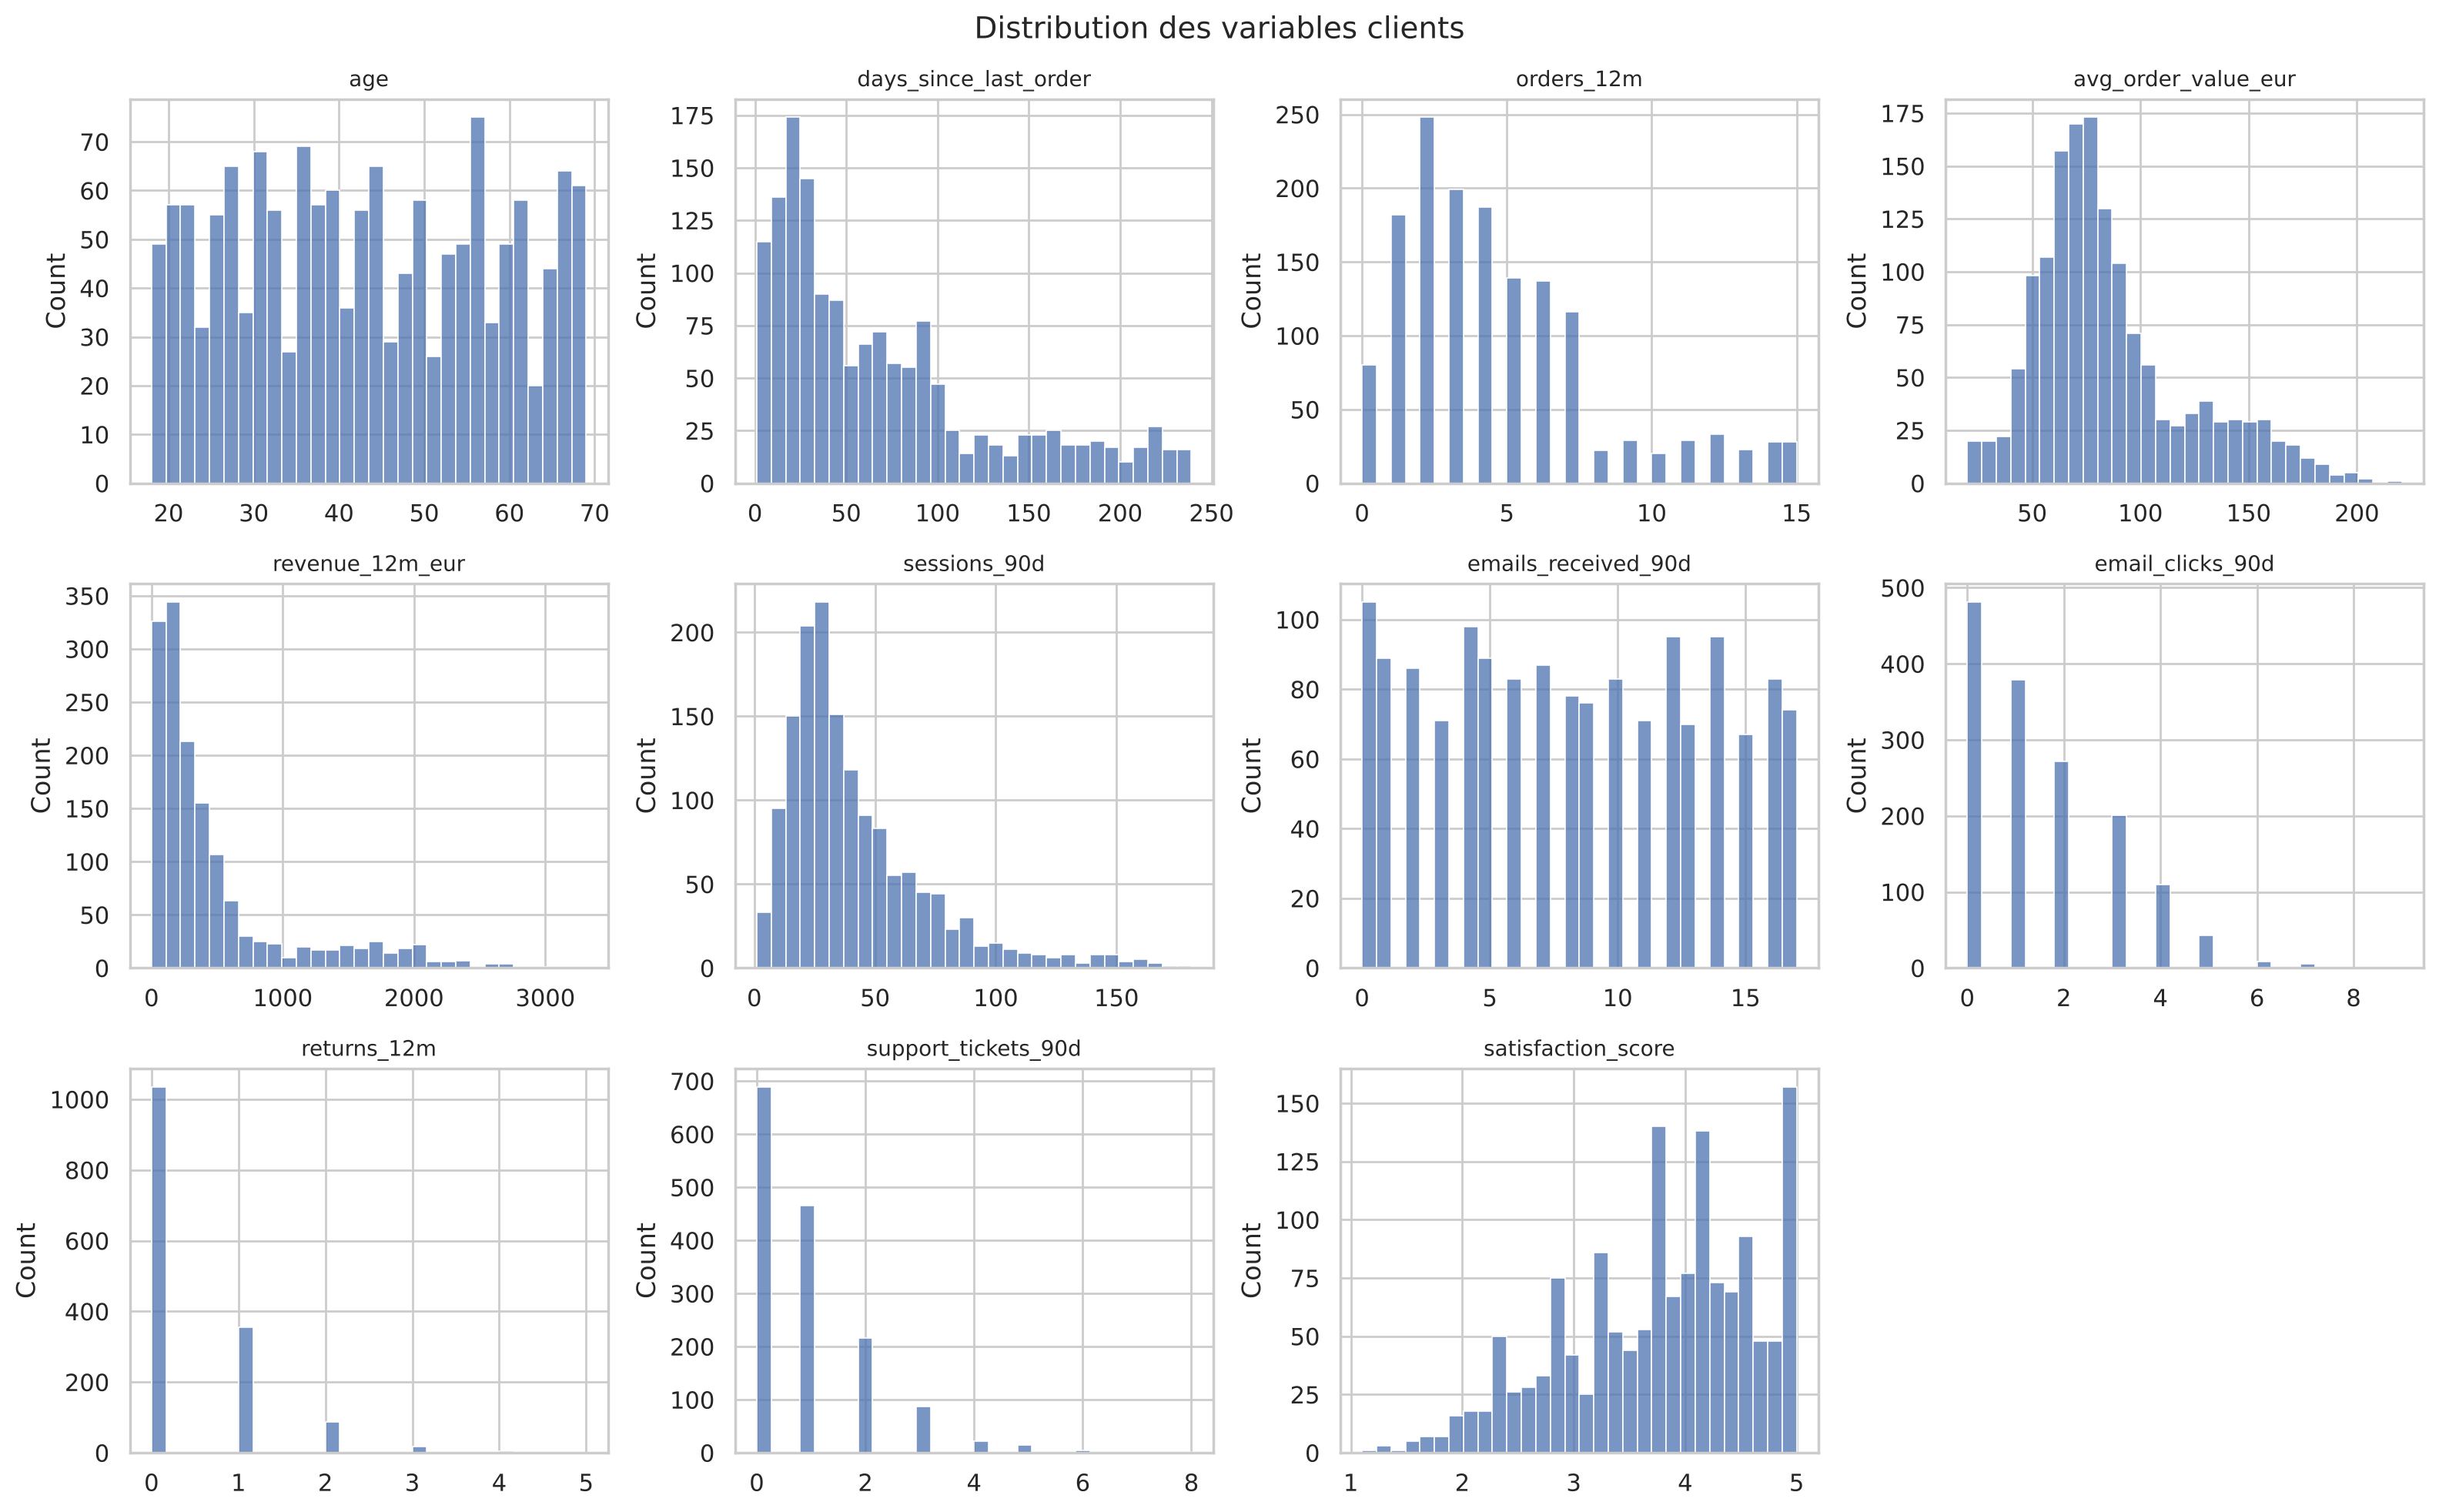

In [11]:
num_cols = ['age', 'days_since_last_order', 'orders_12m', 'avg_order_value_eur', 'revenue_12m_eur',
            'sessions_90d', 'emails_received_90d', 'email_clicks_90d', 'returns_12m',
            'support_tickets_90d', 'satisfaction_score']

fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, col in zip(axes.flat, num_cols):
    sns.histplot(customers[col], bins=30, ax=ax, color='#4C72B0')
    ax.set_title(col, fontsize=10)
    ax.set_xlabel('')
axes.flat[-1].axis('off')
plt.suptitle('Distribution des variables clients', fontsize=14)
plt.tight_layout()
plt.show()

In [12]:
# Asymétrie (skewness) et valeurs extrêmes selon la règle de l'IQR (1,5 × écart interquartile)
def nb_extremes(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

stats = pd.DataFrame({
    'asymétrie': customers[num_cols].skew().round(2),
    'valeurs_extrêmes_IQR': customers[num_cols].apply(nb_extremes),
}).sort_values('asymétrie', ascending=False)
stats

,asymétrie,valeurs_extrêmes_IQR
revenue_12m_eur,1.97,202
returns_12m,1.96,22
support_tickets_90d,1.71,130
sessions_90d,1.65,79
orders_12m,1.20,79
days_since_last_order,1.11,76
avg_order_value_eur,0.99,95
email_clicks_90d,0.92,14
age,0.07,0
emails_received_90d,0.05,0


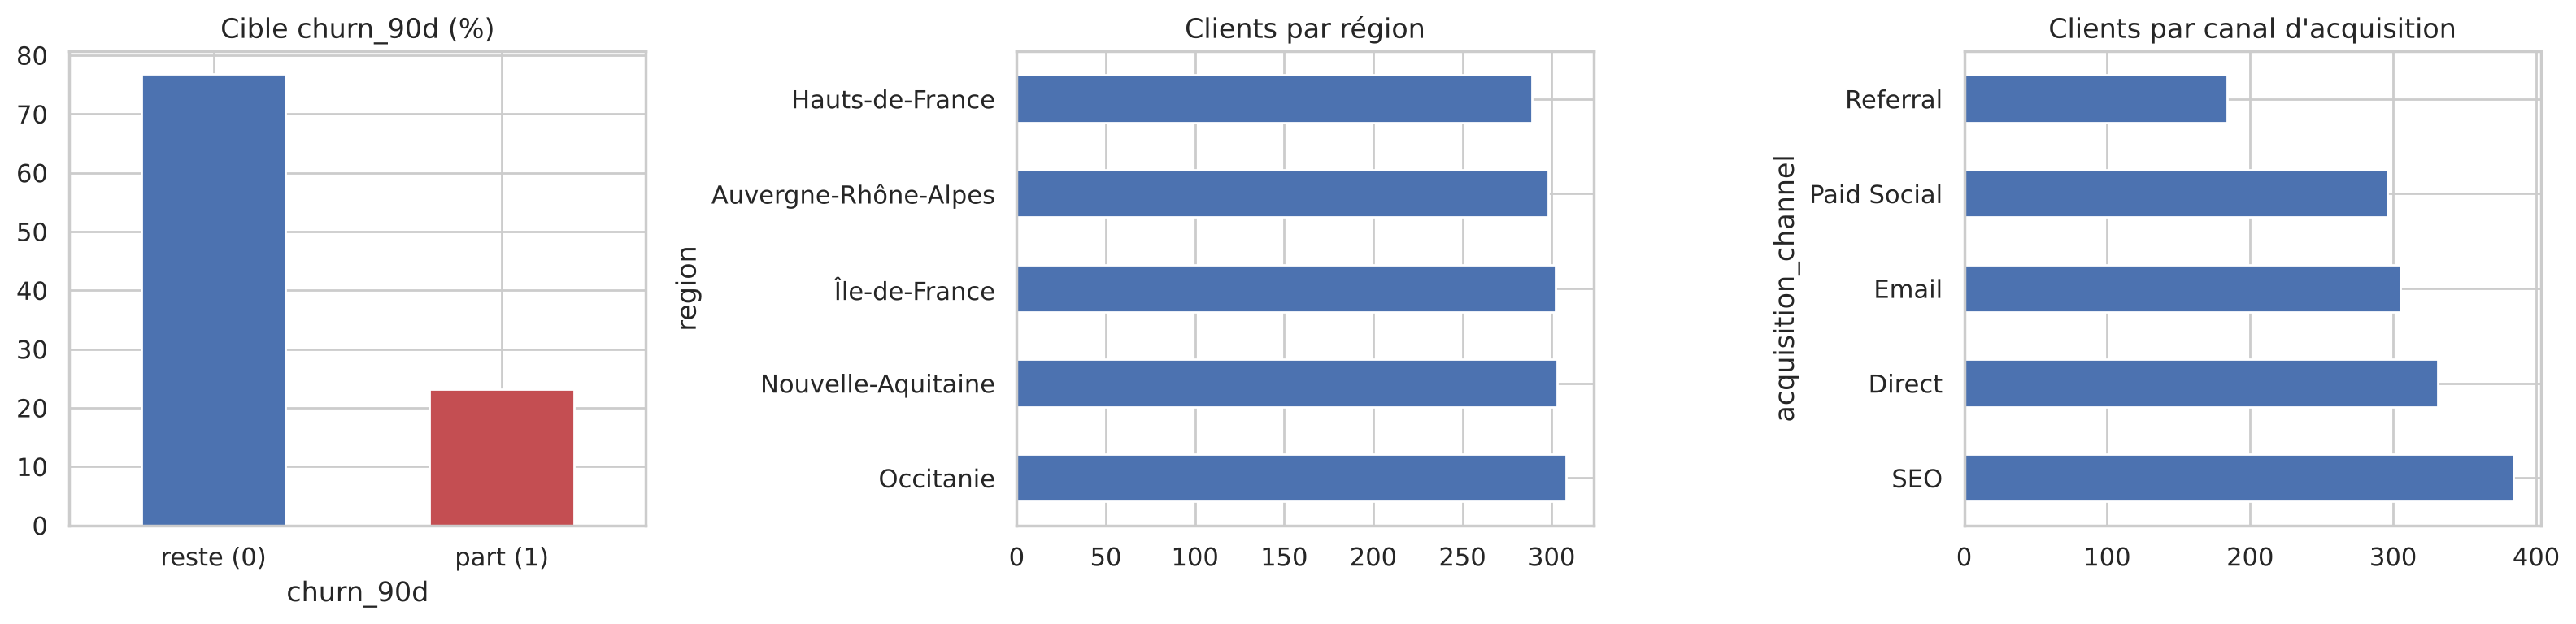

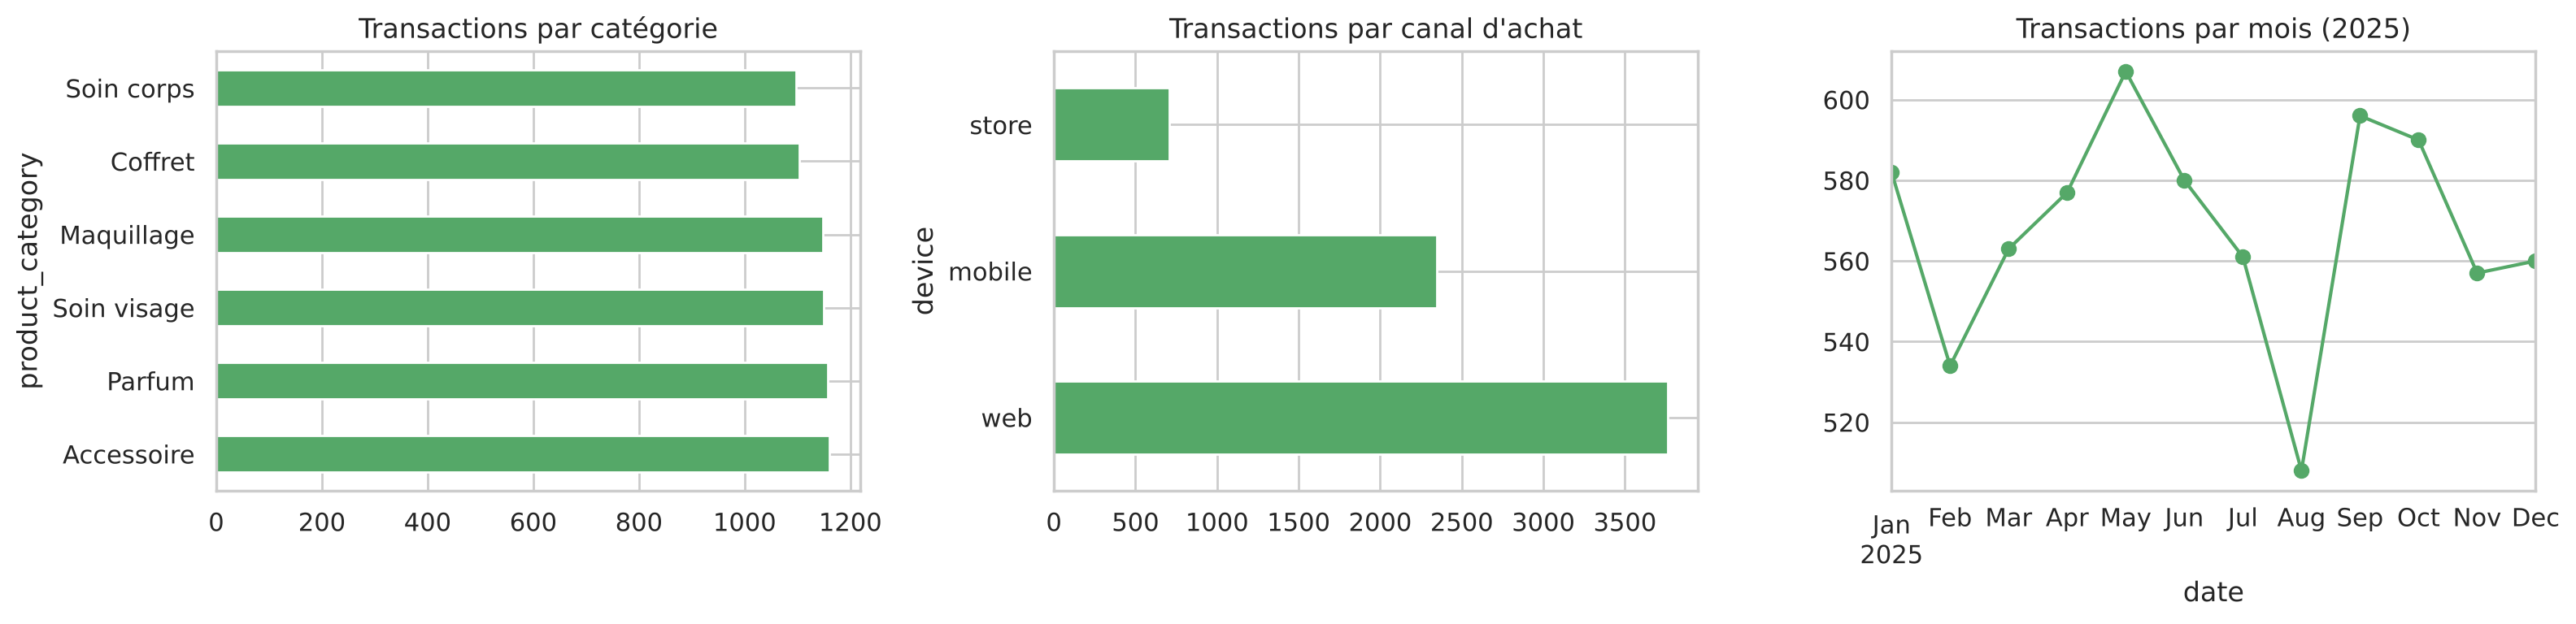

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
customers['churn_90d'].value_counts(normalize=True).mul(100).plot.bar(ax=axes[0], color=['#4C72B0', '#C44E52'])
axes[0].set_title('Cible churn_90d (%)'); axes[0].set_xticklabels(['reste (0)', 'part (1)'], rotation=0)
customers['region'].value_counts().plot.barh(ax=axes[1], color='#4C72B0'); axes[1].set_title('Clients par région')
customers['acquisition_channel'].value_counts().plot.barh(ax=axes[2], color='#4C72B0'); axes[2].set_title("Clients par canal d'acquisition")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
transactions['product_category'].value_counts().plot.barh(ax=axes[0], color='#55A868'); axes[0].set_title('Transactions par catégorie')
transactions['device'].value_counts().plot.barh(ax=axes[1], color='#55A868'); axes[1].set_title("Transactions par canal d'achat")
pd.to_datetime(transactions['date']).dt.to_period('M').value_counts().sort_index().plot(ax=axes[2], marker='o', color='#55A868')
axes[2].set_title('Transactions par mois (2025)')
plt.tight_layout(); plt.show()

**Constat :**
- La cible est **déséquilibrée** : 23,2 % de churn. En mission 4, il faudra une séparation stratifiée et des métriques autres que l'accuracy.
- **Le CA, les sessions et la récence sont très asymétriques** : beaucoup de petites valeurs, quelques très grandes. On crée une version en logarithme pour le clustering (étape 7).
- Les valeurs extrêmes repérées par l'IQR sont **plausibles** (gros clients, clients très actifs) : on les **garde**, car ce sont souvent les clients les plus précieux.
- Régions, canaux d'acquisition et catégories sont **répartis de façon presque égale**, ce qui est typique d'un jeu synthétique (voir étape 9).

## 7. Transformations et préparation
On ne modifie jamais les fichiers bruts : on crée une **copie préparée** de la table clients.

In [14]:
# 7.1 Conversion des dates
transactions['date'] = pd.to_datetime(transactions['date'])
reviews['date'] = pd.to_datetime(reviews['date'])
content['publication_date'] = pd.to_datetime(content['publication_date'])

# 7.2 Typage des variables catégorielles
for col in ['region', 'acquisition_channel']:
    customers[col] = customers[col].astype('category')
for col in ['product_category', 'device']:
    transactions[col] = transactions[col].astype('category')

# 7.3 Clients sans commande : panier moyen remis à 0 (CA = 0)
prep = customers.copy()
prep.loc[prep['sans_commande'], 'avg_order_value_eur'] = 0.0
prep['sans_commande'] = prep['sans_commande'].astype(int)

# 7.4 Variables issues des transactions
agg = transactions.groupby('customer_id').agg(
    nb_categories=('product_category', 'nunique'),
    categorie_principale=('product_category', lambda s: s.value_counts().idxmax()),
    part_achats_mobile=('device', lambda s: (s == 'mobile').mean()),
    part_achats_magasin=('device', lambda s: (s == 'store').mean()),
)
prep = prep.merge(agg, left_on='customer_id', right_index=True, how='left')
prep['nb_categories'] = prep['nb_categories'].fillna(0).astype(int)
prep['categorie_principale'] = prep['categorie_principale'].astype(object).fillna('Aucune')
prep[['part_achats_mobile', 'part_achats_magasin']] = prep[['part_achats_mobile', 'part_achats_magasin']].fillna(0).round(3)

# 7.5 Taux de clic email (0 si aucun email reçu)
prep['taux_clic_email'] = np.where(prep['emails_received_90d'] > 0,
                                   prep['email_clicks_90d'] / prep['emails_received_90d'], 0).round(3)

# 7.6 Versions logarithmiques des variables très asymétriques (pour le clustering)
for col in ['revenue_12m_eur', 'sessions_90d', 'days_since_last_order']:
    prep[f'log_{col}'] = np.log1p(prep[col]).round(4)

prep.to_csv(os.path.join(OUT, 'customers_prepared.csv'), index=False)
print('Table préparée :', prep.shape)
prep.head()

Table préparée : (1500, 24)


,customer_id,age,region,acquisition_channel,days_since_last_order,orders_12m,avg_order_value_eur,revenue_12m_eur,sessions_90d,emails_received_90d,email_clicks_90d,returns_12m,support_tickets_90d,satisfaction_score,churn_90d,sans_commande,nb_categories,categorie_principale,part_achats_mobile,part_achats_magasin,taux_clic_email,log_revenue_12m_eur,log_sessions_90d,log_days_since_last_order
0,C00001,58,Hauts-de-France,Direct,166,3,44.18,132.55,28,13,4,1,3,2.4,1,0,3,Maquillage,0.333,0.000,0.308,4.8945,3.3673,5.1180
1,C00002,52,Occitanie,Email,55,4,74.79,299.16,52,5,0,0,0,3.1,0,0,2,Coffret,0.250,0.250,0.000,5.7043,3.9703,4.0254
2,C00003,66,Nouvelle-Aquitaine,SEO,13,2,75.32,150.63,9,1,0,0,1,4.2,0,0,1,Parfum,0.000,0.000,0.000,5.0214,2.3026,2.6391
3,C00004,67,Hauts-de-France,Direct,107,1,39.36,39.36,10,13,1,1,2,2.4,1,0,1,Soin corps,0.000,1.000,0.077,3.6978,2.3979,4.6821
4,C00005,54,Île-de-France,SEO,34,11,159.17,1750.88,88,3,0,1,1,5.0,0,0,5,Accessoire,0.455,0.182,0.000,7.4684,4.4886,3.5553


## 8. Journal des transformations

In [15]:
journal = pd.DataFrame([
    ('Toutes', 'Aucun doublon, aucune valeur manquante', 'Aucune suppression', 'Contrôle étape 2'),
    ('transactions, reviews, content', 'Dates stockées en texte', 'Conversion en datetime', 'Calculs temporels possibles'),
    ('customers, transactions', 'Variables catégorielles en texte', 'Type category', 'Préparer l\'encodage (missions 3-4)'),
    ('customers', '80 clients à 0 commande avec un panier moyen non nul', 'Panier moyen mis à 0 + indicateur sans_commande', 'Cohérence avec CA = 0 ; segment à part en mission 3'),
    ('customers / transactions', 'Somme des transactions ≠ revenue_12m (écart moyen ≈ 25 €)', 'customers.csv retenu comme référence', 'C\'est la table qui porte la cible churn'),
    ('customers / transactions', 'Récence non recalculable depuis les transactions', 'days_since_last_order conservé tel quel', 'Date de référence inconnue'),
    ('customers', 'revenue = orders × panier moyen (redondance)', 'Ne pas utiliser les 3 ensemble en clustering', 'Éviter de compter 2 fois la même information'),
    ('customers', 'CA, sessions, récence très asymétriques', 'Ajout de log_revenue, log_sessions, log_days', 'Limiter le poids des valeurs extrêmes en K-Means'),
    ('customers', 'Valeurs extrêmes (IQR)', 'Conservées', 'Plausibles : gros clients'),
    ('customers + transactions', 'Comportement d\'achat absent de customers', 'Ajout nb_categories, categorie_principale, parts mobile/magasin', 'Utile pour segmentation et recommandation'),
    ('customers', 'Engagement email brut', 'Ajout taux_clic_email', 'Indicateur comparable entre clients'),
], columns=['fichier', 'constat', 'transformation', 'justification'])

journal.to_csv(os.path.join(OUT, 'audit_journal_transformations.csv'), index=False)
journal

,fichier,constat,transformation,justification
0,Toutes,"Aucun doublon, aucune valeur manquante",Aucune suppression,Contrôle étape 2
1,"transactions, reviews, content",Dates stockées en texte,Conversion en datetime,Calculs temporels possibles
2,"customers, transactions",Variables catégorielles en texte,Type category,Préparer l'encodage (missions 3-4)
3,customers,80 clients à 0 commande avec un panier moyen n...,Panier moyen mis à 0 + indicateur sans_commande,Cohérence avec CA = 0 ; segment à part en miss...
4,customers / transactions,Somme des transactions ≠ revenue_12m (écart mo...,customers.csv retenu comme référence,C'est la table qui porte la cible churn
5,customers / transactions,Récence non recalculable depuis les transactions,days_since_last_order conservé tel quel,Date de référence inconnue
6,customers,revenue = orders × panier moyen (redondance),Ne pas utiliser les 3 ensemble en clustering,Éviter de compter 2 fois la même information
7,customers,"CA, sessions, récence très asymétriques","Ajout de log_revenue, log_sessions, log_days",Limiter le poids des valeurs extrêmes en K-Means
8,customers,Valeurs extrêmes (IQR),Conservées,Plausibles : gros clients
9,customers + transactions,Comportement d'achat absent de customers,"Ajout nb_categories, categorie_principale, par...",Utile pour segmentation et recommandation


## 9. Limites de représentativité

In [16]:
print('Part de chaque région (%) :')
display(customers['region'].value_counts(normalize=True).mul(100).round(1).to_frame('%'))
print('Nombre de textes d\'avis différents :', reviews['review_text'].nunique(), 'pour', len(reviews), 'avis')
print('Posts par canal × format :')
display(pd.crosstab(content['channel'], content['content_type']))

Part de chaque région (%) :


,%
region,
Occitanie,20.5
Nouvelle-Aquitaine,20.2
Île-de-France,20.1
Auvergne-Rhône-Alpes,19.9
Hauts-de-France,19.3


Nombre de textes d'avis différents : 10 pour 700 avis
Posts par canal × format :


content_type,education,product,promotion,storytelling
channel,,,,
Blog,4,3,1,4
Instagram,2,3,3,7
LinkedIn,2,2,5,2
Newsletter,2,1,3,1


- **Données synthétiques.** Les répartitions sont artificiellement régulières : 5 régions à environ 20 % chacune, 6 catégories presque égales. Une vraie base e-commerce est beaucoup plus concentrée, par exemple en Île-de-France.
- **Une seule année (2025).** Pas de comparaison d'une année sur l'autre ni de vraie saisonnalité.
- **Avis non représentatifs.** 700 avis, mais **seulement 10 phrases différentes**. Aucune nuance, ironie ou faute de frappe : l'analyse de sentiment paraîtra plus facile qu'en réalité.
- **Contenus trop peu nombreux.** 45 posts seulement, et parfois **1 seul post** par combinaison canal × format. Toute comparaison reste indicative.
- **Proxy de mesure.** La portée remplace les impressions dans le CTR, ce qui sous-estime probablement le vrai CTR.
- **Définition du churn inconnue.** On ne sait pas comment `churn_90d` a été construit. Si elle dépend de la récence, `days_since_last_order` risquera d'« annoncer » la réponse au modèle (à discuter en mission 4).
- **Variables absentes** : marge, coût d'acquisition par client, consentement marketing, historique de prix et promotions.

## 10. Synthèse de l'audit

| Point | Résultat | Conséquence pour la suite |
|---|---|---|
| Doublons, valeurs manquantes | Aucun | Pas de suppression |
| Bornes (20 règles) | Toutes respectées | Données exploitables |
| Identifiants entre fichiers | Cohérents | Jointures fiables |
| Montants et récence entre fichiers | Écarts | customers.csv = référence par client |
| 80 clients sans commande | Incohérents, profil de nouveaux clients | Segment à part, démarrage à froid |
| Asymétrie | CA, sessions, récence | Versions log pour le K-Means |
| Cible churn | 23,2 % | Stratification, recall, F1, ROC-AUC |
| Représentativité | Faible (synthétique) | Résultats indicatifs, pas de décision réelle |

**Fichiers produits dans `outputs/` :**
- `customers_prepared.csv` : table clients préparée (base des missions 3 et 4) ;
- `audit_journal_transformations.csv` : journal des transformations.